In [3]:
import numpy as np
import matplotlib.pyplot as plt

In [14]:
# system parameters and propagator
# parameter vector: [d_r, d_p, b_r, k_m]
PARAM_NAMES = ["d_r", "d_p", "b_r", "k_m"]
# Mean values at initialisation
param_avg = np.array([0.0956, 0.0214, 0.0965, 0.0116])

# additive Gaussian noise on the normalised states (R^eta)
sigma_s = np.array([0.01, 0.01, 0.01])

# parameter random-walk std per step (R^rho)
sigma_p = np.array([0.2539, 0.0127, 0.0037, 0.2587]) * 1e-3

# Prior std of the initial parameter guess
sigma_theta = np.array([1.0155, 0.0509, 0.0150, 1.0347]) * 1e-3

# R^gamma : measurement-noise std on the fluorescent readout G.
sigma_meas = 0.0025

# timing (all in MINUTES)
Ts = 10.0                 # coarse sampling / control interval [min]
T_TOTAL = 1200.0          # total simulated duration [min] (20 hours)
tN = int(round(T_TOTAL / Ts)) + 1     # number of time points (k = 0 .. tN-1)
PERIOD = 300.0            # target oscillation period [min]

# control range
# Light only increases transcription, so u >= 0. The target stays at or above
# the light-free equilibrium G=1, so it is reachable with non-negative control.
U_MIN, U_MAX = 0.0, 4.0

def target(t):
    """Desired mature-GFP fold-change as a function of time t [minutes]."""
    return 2.2 - 0.8 * np.cos(2.0 * np.pi * t / PERIOD)

# Discretize the continuous-time model with a matrix exponential
# written in the form where 'theta' is a 2-d array of shape (..., 4) with the parameters [d_r, d_p, b_r, k_m] in the last dimension
# this accommodates the particle filter, which has multiple parameter particles, each with its own theta vector
def discretize(theta):
    """Return (A_d, e, b_u) for the discrete affine system y+ = A_d y + e + b_u*u."""
    theta = np.asarray(theta, dtype=float)
    dr = theta[..., 0]
    dp = theta[..., 1]
    br = theta[..., 2]
    km = theta[..., 3]

    a = dr            # eigenvalue -d_r  (R decay)
    p = dp            # eigenvalue -d_p  (G decay)
    m = dp + km       # eigenvalue -(d_p+k_m)  (P decay)

    ea = np.exp(-a * Ts)
    em = np.exp(-m * Ts)
    ep = np.exp(-p * Ts)

    # sub-diagonal entries of A_k (lower-triangular matrix exponential)
    A10 = m / (m - a) * (ea - em)
    A21 = p / (p - m) * (em - ep)
    A20 = p * m / (m - a) * ((ea - ep) / (p - a) - (em - ep) / (p - m))

    zero = np.zeros_like(ea)
    A_d = np.stack([
        np.stack([ea,  zero, zero], axis=-1),
        np.stack([A10, em,   zero], axis=-1),
        np.stack([A20, A21,  ep],   axis=-1),
    ], axis=-2)                                   # (..., 3, 3)

    # first column of A^{-1}(A_k - I)
    col0 = -(ea - 1.0) / a
    col1 = col0 - A10 / m
    col2 = col1 - A20 / p
    m0 = np.stack([col0, col1, col2], axis=-1)    # (..., 3)

    b_u = br[..., None] * m0
    e = a[..., None] * m0
    return A_d, e, b_u


def step_state(Y, theta, u):
    """One deterministic step y_{k+1} = A_d y + e + b_u*u (no noise added)."""
    A_d, e, b_u = discretize(theta)
    AY = np.einsum("...ij,...j->...i", A_d, np.asarray(Y, dtype=float))
    return AY + e + b_u * np.asarray(u)[..., None]

In [5]:
# linear-quadratic regulator (LQR) design for the linearized system

def lqr_control(y0, theta_hat, future_targets, q=1.0, C_u=1e-2):
    """Optimal first control over the horizon defined by `future_targets`

    Parameters
    ----------
    y0            : current best state estimate (3,)            [x_0]
    theta_hat     : current best parameter estimate (4,) -> fixes A_k, e, b_u
    future_targets: G targets for x_1 .. x_H (length H = horizon)
    q             : weight on the tracked output G in C_y
    C_u           : scalar control-effort weight

    Only the G component is tracked, so C_y = q * diag(0,0,1) and the target
    state enters only through its G entry.
    """
    A_d, e, b_u = discretize(np.asarray(theta_hat, float))   # single model
    y0 = np.asarray(y0, float)
    H = len(future_targets)

    I = np.eye(3)
    Cy = np.diag([0.0, 0.0, q])              # track G only
    B = b_u.reshape(3, 1)

    def target_vec(g):                       # state-space target (G entry only)
        return np.array([0.0, 0.0, g])

    # terminal cost at x_H : S_H = C_y, s_H = -C_y y_H*
    S = Cy.copy()
    s = -Cy @ target_vec(future_targets[H - 1])

    # backward recursion: turn (S_{i+1}, s_{i+1}) into (S_i, s_i) for i=H-1..1,
    # leaving (S_1, s_1) after the loop.
    for i in range(H - 1, 0, -1):
        M = C_u + (B.T @ S @ B)[0, 0]
        W = I - (S @ B @ B.T) / M
        S_new = Cy + A_d.T @ W @ S @ A_d
        s_new = -Cy @ target_vec(future_targets[i - 1]) + A_d.T @ W @ (s + S @ e)
        S, s = S_new, s_new

    # optimal first control from (S_1, s_1)
    M0 = C_u + (B.T @ S @ B)[0, 0]
    u0 = -(B.T @ (S @ (A_d @ y0 + e) + s))[0] / M0

    return float(np.clip(u0, U_MIN, U_MAX))

In [6]:
# particle filter for state and parameter estimation

class ParticleFilter:
    def __init__(self, n_particles=2000, rng=None):
        self.N = n_particles
        self.rng = np.random.default_rng() if rng is None else rng
        # States start at the normalised equilibrium [1,1,1]; parameters from
        # the Gaussian prior N(param_avg, sigma_theta^2).
        self.Y = np.ones((self.N, 3))
        self.theta = param_avg + self.rng.standard_normal((self.N, 4)) * sigma_theta

    def update(self, u, z):
        """Assimilate one measurement z, given the control u just applied."""
        # (i) propagate: parameter random walk (R^rho) + state noise (R^eta).
        theta_pred = self.theta + self.rng.standard_normal((self.N, 4)) * sigma_p
        Y_pred = step_state(self.Y, theta_pred, u)
        Y_pred = Y_pred + self.rng.standard_normal((self.N, 3)) * sigma_s

        # (ii) weight by the Gaussian measurement likelihood of G vs z.
        # Work in log-space, subtract the max for numerical stability.
        resid = Y_pred[:, 2] - z
        logw = -0.5 * (resid / sigma_meas) ** 2
        w = np.exp(logw - logw.max())
        w /= w.sum()

        # (iii) resample particles in proportion to their weights.
        idx = self.rng.choice(self.N, size=self.N, replace=True, p=w)
        self.Y = Y_pred[idx]
        self.theta = theta_pred[idx]

    # --- ensemble reductions used by the controller and for plotting --------
    def state_mean(self):
        return self.Y.mean(axis=0)

    def theta_mean(self):
        return self.theta.mean(axis=0)

    def theta_std(self):
        return self.theta.std(axis=0)

In [18]:
# setup and run the simulation with lqr controller

rng = np.random.default_rng(0)  # for reproducibility

# number of steps to look ahead in the MPC optimization
horizon=10

pf = ParticleFilter(rng=rng)
y_true = np.ones(3) # initial true state (normalised equilibrium, all 1's)
theta_true = param_avg.copy()

# track the true and measured GFP, the target, the applied control, and the parameter estimates
G_actual = np.zeros(tN)
G_meas = np.zeros(tN)
targets = np.zeros(tN)
U = np.zeros(tN)
theta_true_rec = np.zeros((tN, 4))
theta_mean_rec = np.zeros((tN, 4))
theta_std_rec = np.zeros((tN, 4))

G_actual[0] = y_true[2]
G_meas[0] = y_true[2]
targets[0] = target(0.0)
theta_true_rec[0] = theta_true
theta_mean_rec[0] = pf.theta_mean()
theta_std_rec[0] = pf.theta_std()

for k in range(1, tN):
    # --- optimal control for the k-1 -> k transition --------------------
    future = np.array([target((k + i) * Ts) for i in range(horizon)])
    u = lqr_control(pf.state_mean(), pf.theta_mean(), future)
    U[k] = u

    # --- advance the true (noisy) system; true parameters/d drift -------
    theta_true = theta_true + rng.standard_normal(4) * sigma_p
    y_true = (step_state(y_true, theta_true, u)
                + rng.standard_normal(3) * sigma_s)
    z = y_true[2] + rng.standard_normal() * sigma_meas

    G_actual[k] = y_true[2]
    G_meas[k] = z
    targets[k] = target(k * Ts)

    # --- particle filter assimilates the new measurement ----------------
    pf.update(u, z)

    theta_true_rec[k] = theta_true
    theta_mean_rec[k] = pf.theta_mean()
    theta_std_rec[k] = pf.theta_std()

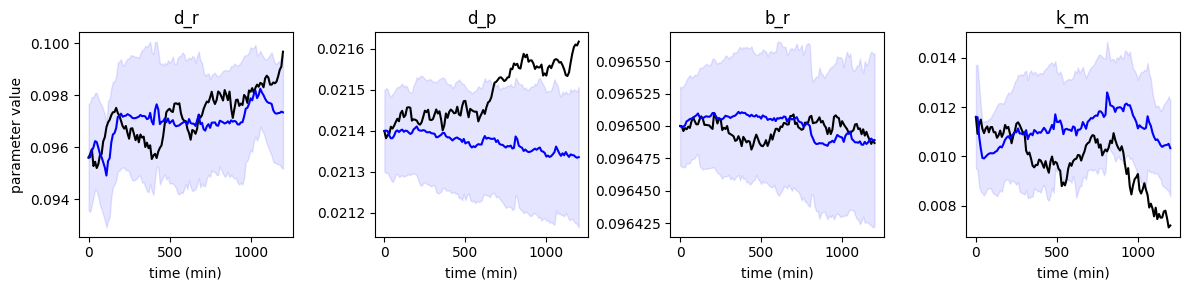

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3), sharex=True)
for i in range(4):
    axes[i].plot(np.arange(tN) * Ts, theta_true_rec[:, i], 'k-', label='true')
    axes[i].plot(np.arange(tN) * Ts, theta_mean_rec[:, i], 'b-', label='mean')
    axes[i].fill_between(np.arange(tN) * Ts,
                         theta_mean_rec[:, i] - 2.0 * theta_std_rec[:, i],
                         theta_mean_rec[:, i] + 2.0 * theta_std_rec[:, i],
                         color='b', alpha=0.1, label='±2σ')
    axes[i].set_title(PARAM_NAMES[i])
    axes[i].set_xlabel('time (min)')
axes[0].set_ylabel('parameter value')

plt.tight_layout()
plt.savefig("GFP_expression_parameters_tracking.png", dpi=300)

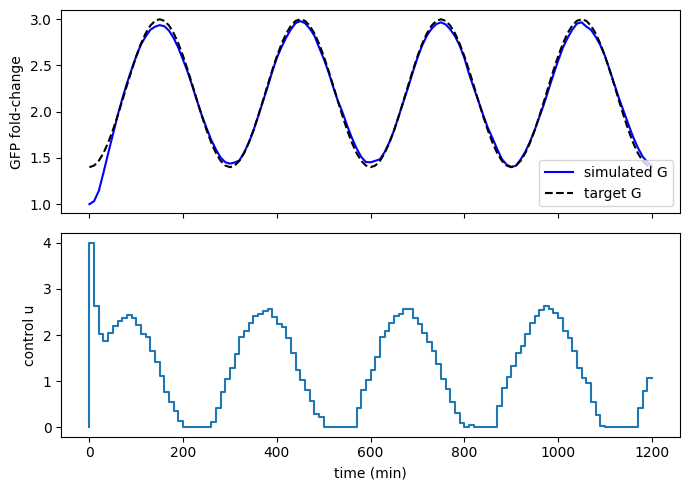

In [27]:
fig, axes = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
axes[0].plot(np.arange(tN) * Ts, G_actual, 'b-', label='simulated G')
axes[0].plot(np.arange(tN) * Ts, targets, 'k--', label='target G')
axes[0].set_ylabel('GFP fold-change')
axes[0].legend()
axes[1].step(np.arange(tN) * Ts, U)
axes[1].set_ylabel('control u')
axes[1].set_xlabel('time (min)')
plt.tight_layout()
plt.savefig("GFP_expression_control.png", dpi=300)